## Проверка гипотез в бизнесе
В этом проекте анализировались данные агрегатора отелей. Цель исследования — обработка, анализ и визуализация данных. Анализ поможет выявить ключевые закономерности и сделать выводы о туризме в субъектах Российской Федерации.

В работе используются следующие наборы данных:

### 1. `hotel.csv`

Таблица содержит информацию о количестве гостиниц, хостелов и санаторно-курортных организаций по субъектам Российской Федерации за 2018–2023 годы.

Основные поля:
- **Субъект** — наименование субъекта Российской Федерации;
- **Число гостиниц**;
- **Число мест в гостиницах**;
- **Число хостелов**;
- **Число мест в хостелах**;
- **Число санаторно-курортных организаций**;
- **Число мест в санаторно-курортных организациях**.

### 2. `count_person_hotel.csv`

Таблица содержит данные о количестве людей, размещённых в гостиницах по субъектам Российской Федерации в 2023 году.

Основные поля:
- **Субъект** — наименование субъекта Российской Федерации;
- **Численность лиц, размещённых в гостиницах в 2023 году**;
- **Численность граждан России, размещённых в гостиницах в 2023 году**;
- **Численность иностранных граждан, размещённых в гостиницах в 2023 году**.

### 3. `tour_firm.csv`

Таблица содержит информацию о количестве реализованных турпакетов в 2018–2023 годах.

Основные поля:
- **Субъект** — наименование субъекта Российской Федерации;
- **Общее число турпакетов, реализованных населению**;
- **Общее число турпакетов, реализованных гражданам России по территории России**;
- **Общее число турпакетов, реализованных гражданам России по другим странам**;
- **Общее число турпакетов, реализованных гражданам других стран по территории России**.

### 4. `tour_cost_2023.csv`

Таблица содержит основные показатели деятельности туристических фирм по субъектам Российской Федерации в 2023 году.

Основные поля:
- **Субъект** — наименование субъекта Российской Федерации;
- **Стоимость реализованных турпакетов в 2023 году, млн руб.**;
- **Стоимость турпакетов, реализованных гражданам России по территории России в 2023 году, млн руб.**;
- **Стоимость турпакетов, реализованных гражданам России по другим странам в 2023 году, млн руб.**


## Задачи исследования

1. Подготовить и проверить данные.
2. Провести исследовательский анализ данных.
3. Изучить динамику показателей туристической отрасли.
4. Определить регионы с наибольшей стоимостью турпакетов.
5. Проверить статистические гипотезы.
6. Сформулировать выводы и рекомендации.

### Шаг 1. Загрузка данных
Загружаем все необходимые данные и знакомимся с содержанием таблиц.

#### Задача 1.1. Импорт библиотеки pandas
Импортируем библиотеку pandas с сокращением pd.

In [1]:
import pandas as pd

In [2]:
df_hotel = pd.read_csv('hotel.csv', sep=';')
df_person_hotel = pd.read_csv('count_person_hotel.csv', sep=';')
df_tour_firm = pd.read_csv('tour_firm.csv', sep=';')
df_tour_cost_2023 = pd.read_csv('tour_cost_2023.csv', sep=';')


### Шаг 2. Предобработка данных
Проверяем названия столбцов и убеждаемся, что они удобны для работы

In [3]:
df_hotel.columns

Index(['Субъект', 'Число гостиниц, 2018', 'Число гостиниц, 2019',
       'Число гостиниц, 2020', 'Число гостиниц, 2021', 'Число гостиниц, 2022',
       'Число гостиниц, 2023', 'Число мест в гостиницах, 2018',
       'Число мест в гостиницах, 2019', 'Число мест в гостиницах, 2020',
       'Число мест в гостиницах, 2021', 'Число мест в гостиницах, 2022',
       'Число мест в гостиницах, 2023', 'Число хостелов, 2018',
       'Число хостелов, 2019', 'Число хостелов, 2020', 'Число хостелов, 2021',
       'Число хостелов, 2022', 'Число хостелов, 2023',
       'Число мест в хостелах, 2018', 'Число мест в хостелах, 2019',
       'Число мест в хостелах, 2020', 'Число мест в хостелах, 2021',
       'Число мест в хостелах, 2022', 'Число мест в хостелах, 2023',
       'Число санаторно-курортных организаций, 2018',
       'Число санаторно-курортных организаций, 2019',
       'Число санаторно-курортных организаций, 2020',
       'Число санаторно-курортных организаций, 2021',
       'Число санаторно-

In [4]:
df_person_hotel.columns

Index(['Субъект', 'Численность лиц, размещенных в гостиницах в 2023 году',
       'Численность граждан России, размещенных в гостиницах в 2023 году',
       'Численность иностранных граждан, размещенных в гостиницах в 2023 году'],
      dtype='object')

In [5]:
df_tour_firm.columns

Index(['Субъект', 'Общее число турпакетов, реализованных населению, 2018',
       'Общее число турпакетов, реализованных гражданам России по территории России, 2018',
       'Общее число турпакетов, реализованных гражданам России по другим странам, 2018',
       'Общее число турпакетов, реализованных гражданам других стран по территории России, 2018',
       'Общее число турпакетов, реализованных населению, 2019',
       'Общее число турпакетов, реализованных гражданам России по территории России, 2019',
       'Общее число турпакетов, реализованных гражданам России по другим странам, 2019',
       'Общее число турпакетов, реализованных гражданам других стран по территории России, 2019',
       'Общее число турпакетов, реализованных населению, 2020',
       'Общее число турпакетов, реализованных гражданам России по территории России, 2020',
       'Общее число турпакетов, реализованных гражданам России по другим странам, 2020',
       'Общее число турпакетов, реализованных гражданам др

In [6]:
df_tour_cost_2023.columns

Index(['Субъект', 'Стоимость реализованных турпакетов в 2023 году, млн руб.',
       'Стоимость турпакетов  реализованных гражданам России по территории России в 2023 году, млн руб.',
       'Стоимость турпакетов  реализованных гражданам России по другим странам в 2023 году, млн руб.'],
      dtype='object')

#### Задача 2.1. Переименование столбцов
Значениям столбцов присвоим новые имена.

In [7]:
df_hotel.columns = [
    'subject',
    'hotels_2018', 'hotels_2019', 'hotels_2020', 'hotels_2021',
    'hotels_2022', 'hotels_2023',
    'hotel_places_2018', 'hotel_places_2019', 'hotel_places_2020',
    'hotel_places_2021', 'hotel_places_2022', 'hotel_places_2023',
    'guests_2018', 'guests_2019', 'guests_2020', 'guests_2021',
    'guests_2022', 'guests_2023',
    'guest_places_2018', 'guest_places_2019', 'guest_places_2020',
    'guest_places_2021', 'guest_places_2022', 'guest_places_2023',
    'sanatoriums_2018', 'sanatoriums_2019', 'sanatoriums_2020',
    'sanatoriums_2021', 'sanatoriums_2022', 'sanatoriums_2023',
    'sanatorium_places_2018', 'sanatorium_places_2019',
    'sanatorium_places_2020', 'sanatorium_places_2021',
    'sanatorium_places_2022', 'sanatorium_places_2023'
]
df_person_hotel.columns = [
    'subject',
    'total_people_2023',
    'russian_people_2023',
    'foreign_people_2023'
]
df_tour_firm.columns = [
    'subject',
    'tours_people_2018',
    'tours_russia_2018',
    'tours_foreign_2018',
    'tours_foreign_in_russia_2018',
    'tours_people_2019',
    'tours_russia_2019',
    'tours_foreign_2019',
    'tours_foreign_in_russia_2019',
    'tours_people_2020',
    'tours_russia_2020',
    'tours_foreign_2020',
    'tours_foreign_in_russia_2020',
    'tours_people_2021',
    'tours_russia_2021',
    'tours_foreign_2021',
    'tours_foreign_in_russia_2021',
    'tours_people_2022',
    'tours_russia_2022',
    'tours_foreign_2022',
    'tours_foreign_in_russia_2022',
    'tours_people_2023',
    'tours_russia_2023',
    'tours_foreign_2023',
    'tours_foreign_in_russia_2023'
]
df_tour_cost_2023.columns = [
    'subject',
    'total_cost_2023',
    'russia_cost_2023',
    'foreign_cost_2023'
]

#### Задача 2.2. Анализ типов данных, пропусков, замена некорректных значений

In [8]:
df_hotel.dtypes

subject                   object
hotels_2018                int64
hotels_2019                int64
hotels_2020                int64
hotels_2021                int64
hotels_2022                int64
hotels_2023                int64
hotel_places_2018          int64
hotel_places_2019          int64
hotel_places_2020          int64
hotel_places_2021          int64
hotel_places_2022          int64
hotel_places_2023          int64
guests_2018                int64
guests_2019                int64
guests_2020                int64
guests_2021                int64
guests_2022                int64
guests_2023                int64
guest_places_2018         object
guest_places_2019         object
guest_places_2020         object
guest_places_2021         object
guest_places_2022         object
guest_places_2023         object
sanatoriums_2018           int64
sanatoriums_2019           int64
sanatoriums_2020           int64
sanatoriums_2021           int64
sanatoriums_2022           int64
sanatorium

In [9]:
df_person_hotel.dtypes

subject                object
total_people_2023       int64
russian_people_2023     int64
foreign_people_2023     int64
dtype: object

In [10]:
df_tour_firm.dtypes

subject                          object
tours_people_2018                object
tours_russia_2018                object
tours_foreign_2018               object
tours_foreign_in_russia_2018    float64
tours_people_2019                object
tours_russia_2019                object
tours_foreign_2019               object
tours_foreign_in_russia_2019     object
tours_people_2020                object
tours_russia_2020                object
tours_foreign_2020               object
tours_foreign_in_russia_2020    float64
tours_people_2021                object
tours_russia_2021                object
tours_foreign_2021              float64
tours_foreign_in_russia_2021     object
tours_people_2022                object
tours_russia_2022                object
tours_foreign_2022               object
tours_foreign_in_russia_2022    float64
tours_people_2023                object
tours_russia_2023                object
tours_foreign_2023              float64
tours_foreign_in_russia_2023    float64


In [11]:
df_tour_cost_2023.dtypes

subject              object
total_cost_2023      object
russia_cost_2023     object
foreign_cost_2023    object
dtype: object

In [12]:
df_hotel.isna().sum()

subject                   0
hotels_2018               0
hotels_2019               0
hotels_2020               0
hotels_2021               0
hotels_2022               0
hotels_2023               0
hotel_places_2018         0
hotel_places_2019         0
hotel_places_2020         0
hotel_places_2021         0
hotel_places_2022         0
hotel_places_2023         0
guests_2018               0
guests_2019               0
guests_2020               0
guests_2021               0
guests_2022               0
guests_2023               0
guest_places_2018         0
guest_places_2019         0
guest_places_2020         0
guest_places_2021         0
guest_places_2022         0
guest_places_2023         0
sanatoriums_2018          0
sanatoriums_2019          0
sanatoriums_2020          0
sanatoriums_2021          0
sanatoriums_2022          0
sanatoriums_2023          0
sanatorium_places_2018    0
sanatorium_places_2019    0
sanatorium_places_2020    0
sanatorium_places_2021    0
sanatorium_places_20

In [13]:
df_person_hotel.isna().sum()

subject                0
total_people_2023      0
russian_people_2023    0
foreign_people_2023    0
dtype: int64

In [14]:
df_tour_firm.isna().sum()

subject                          0
tours_people_2018                0
tours_russia_2018                0
tours_foreign_2018               1
tours_foreign_in_russia_2018    20
tours_people_2019                0
tours_russia_2019                0
tours_foreign_2019               0
tours_foreign_in_russia_2019    19
tours_people_2020                0
tours_russia_2020                0
tours_foreign_2020               0
tours_foreign_in_russia_2020    39
tours_people_2021                1
tours_russia_2021                1
tours_foreign_2021               2
tours_foreign_in_russia_2021    37
tours_people_2022                0
tours_russia_2022                0
tours_foreign_2022               1
tours_foreign_in_russia_2022    40
tours_people_2023                0
tours_russia_2023                0
tours_foreign_2023               1
tours_foreign_in_russia_2023    39
dtype: int64

In [15]:
df_tour_cost_2023.isna().sum()

subject              0
total_cost_2023      0
russia_cost_2023     0
foreign_cost_2023    0
dtype: int64

#### Находим столбцы со строковым типом данных.
#### Проверяем их, чтобы понять, действительно ли в них должен быть текст.

In [16]:
df_hotel.select_dtypes(include='object').columns

Index(['subject', 'guest_places_2018', 'guest_places_2019',
       'guest_places_2020', 'guest_places_2021', 'guest_places_2022',
       'guest_places_2023', 'sanatorium_places_2018', 'sanatorium_places_2019',
       'sanatorium_places_2020', 'sanatorium_places_2021',
       'sanatorium_places_2022', 'sanatorium_places_2023'],
      dtype='object')

Выбираем столбцы, в которых хранится количество мест.
Эти данные должны иметь числовой тип.


In [17]:
places_cols = [col for col in df_hotel.columns
    if 'guest_places' in col or 'sanatorium_places' in col]
places_cols

['guest_places_2018',
 'guest_places_2019',
 'guest_places_2020',
 'guest_places_2021',
 'guest_places_2022',
 'guest_places_2023',
 'sanatorium_places_2018',
 'sanatorium_places_2019',
 'sanatorium_places_2020',
 'sanatorium_places_2021',
 'sanatorium_places_2022',
 'sanatorium_places_2023']

In [18]:
df_hotel[places_cols].dtypes

guest_places_2018         object
guest_places_2019         object
guest_places_2020         object
guest_places_2021         object
guest_places_2022         object
guest_places_2023         object
sanatorium_places_2018    object
sanatorium_places_2019    object
sanatorium_places_2020    object
sanatorium_places_2021    object
sanatorium_places_2022    object
sanatorium_places_2023    object
dtype: object

Приводим столбцы с количеством мест к числовому типу

In [19]:
df_hotel[places_cols] = df_hotel[places_cols].apply(pd.to_numeric, errors='coerce')

In [20]:
df_hotel[places_cols].dtypes

guest_places_2018         float64
guest_places_2019         float64
guest_places_2020         float64
guest_places_2021         float64
guest_places_2022         float64
guest_places_2023         float64
sanatorium_places_2018    float64
sanatorium_places_2019    float64
sanatorium_places_2020    float64
sanatorium_places_2021    float64
sanatorium_places_2022    float64
sanatorium_places_2023    float64
dtype: object

Проверяем минимальные значения в столбцах с количеством мест

In [21]:
df_hotel[places_cols].min()

guest_places_2018           0.0
guest_places_2019           0.0
guest_places_2020           0.0
guest_places_2021           0.0
guest_places_2022           0.0
guest_places_2023           0.0
sanatorium_places_2018    510.0
sanatorium_places_2019    501.0
sanatorium_places_2020    512.0
sanatorium_places_2021    485.0
sanatorium_places_2022    485.0
sanatorium_places_2023    383.0
dtype: float64

Проверяем количество пропусков после преобразования столбцов в числовой тип

In [22]:
df_hotel[places_cols].isna().sum()

guest_places_2018         13
guest_places_2019         13
guest_places_2020         19
guest_places_2021         12
guest_places_2022          8
guest_places_2023          9
sanatorium_places_2018    11
sanatorium_places_2019    11
sanatorium_places_2020    10
sanatorium_places_2021    12
sanatorium_places_2022    12
sanatorium_places_2023    10
dtype: int64

В столбцах с количеством мест обнаружены некорректные значения, которые при преобразовании в числовой формат были заменены на пропуски (NaN). Требуется определить природу этих значений и принять решение об их обработке.

In [23]:
# Находим строки с некорректными значениями в столбцах с количеством мест
df_hotel[df_hotel[places_cols].isna().any(axis=1)][places_cols]

,guest_places_2018,guest_places_2019,guest_places_2020,guest_places_2021,guest_places_2022,guest_places_2023,sanatorium_places_2018,sanatorium_places_2019,sanatorium_places_2020,sanatorium_places_2021,sanatorium_places_2022,sanatorium_places_2023
1,0.0,0.0,0.0,0.0,NaN,NaN,2953.0,2829.0,2430.0,2837.0,2672.0,2937.0
7,NaN,NaN,476.0,932.0,922.0,929.0,1507.0,1557.0,1552.0,1082.0,1202.0,1252.0
8,350.0,382.0,453.0,486.0,403.0,565.0,NaN,NaN,NaN,NaN,NaN,NaN
10,NaN,NaN,NaN,NaN,267.0,358.0,NaN,NaN,NaN,NaN,NaN,NaN
13,NaN,158.0,NaN,NaN,NaN,NaN,1205.0,1199.0,1146.0,1146.0,1154.0,1331.0
18,284.0,306.0,328.0,406.0,387.0,482.0,821.0,789.0,787.0,NaN,NaN,NaN
19,163.0,249.0,334.0,452.0,436.0,500.0,1237.0,1237.0,989.0,NaN,NaN,873.0
26,221.0,250.0,267.0,219.0,241.0,177.0,1422.0,1392.0,1879.0,1652.0,1664.0,NaN
28,NaN,NaN,NaN,0.0,0.0,NaN,517.0,517.0,517.0,485.0,485.0,485.0
29,NaN,NaN,NaN,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN


In [24]:
# Рассчитываем долю пропусков в каждом столбце
df_hotel[places_cols].isna().mean() * 100

guest_places_2018         16.049383
guest_places_2019         16.049383
guest_places_2020         23.456790
guest_places_2021         14.814815
guest_places_2022          9.876543
guest_places_2023         11.111111
sanatorium_places_2018    13.580247
sanatorium_places_2019    13.580247
sanatorium_places_2020    12.345679
sanatorium_places_2021    14.814815
sanatorium_places_2022    14.814815
sanatorium_places_2023    12.345679
dtype: float64

В столбцах с количеством мест обнаружены пропуски: их доля составляет примерно 10–23% в зависимости от года и типа организации. Удаление строк с пропусками приведёт к существенной потере данных, поэтому необходимо определить причину пропусков и выбрать подходящий способ их обработки.

In [25]:
# Проверяем уникальные значения в столбцах с количеством мест
for col in places_cols:
    print(col)
    print(df_hotel[col].unique())
    print()

guest_places_2018
[1.9200e+02 0.0000e+00 9.5400e+02 1.2570e+03 1.8400e+02 4.3200e+02
 3.5600e+02        nan 3.5000e+02 5.8220e+03 3.5200e+02 2.2600e+02
 4.9100e+02 3.4100e+02 4.2800e+02 9.4749e+04 2.8400e+02 1.6300e+02
 1.9500e+02 1.3980e+03 1.0590e+03 6.7500e+02 8.1400e+02 4.3900e+02
 2.2100e+02 8.8330e+03 1.1440e+03 6.2910e+03 1.3600e+02 1.4940e+03
 1.1830e+03 1.5100e+02 3.7500e+02 6.4800e+02 6.6700e+02 7.4100e+02
 3.8150e+03 3.2900e+02 2.0600e+02 8.5400e+02 1.7300e+02 2.7310e+03
 5.8900e+02 1.1780e+03 1.6610e+03 1.5000e+02 1.9900e+02 2.6710e+03
 1.3990e+03 4.8300e+02 5.7100e+02 1.0810e+03 5.9700e+02 7.8700e+02
 8.0600e+02 3.0700e+02 4.6600e+02 8.3000e+01 1.3400e+02 2.6100e+02
 6.6200e+02 9.2400e+02 1.0600e+02 2.5600e+02]

guest_places_2019
[  288.     0.   914.   505.   144.   583.   336.    nan   382. 11083.
   467.   304.   158.  1086.   432.   489. 81148.   306.   249.   420.
  1145.  1552.  1523.   642.   417.   250.  7522.  2109.  9099.   102.
  1076.   953.   350.   401.   925

In [26]:
# Приводим столбцы со стоимостью турпакетов к числовому типу
df_tour_cost_2023[['total_cost_2023', 'russia_cost_2023', 'foreign_cost_2023']] = (
    df_tour_cost_2023[['total_cost_2023', 'russia_cost_2023', 'foreign_cost_2023']]
        .apply(pd.to_numeric, errors='coerce')
)

# Проверяем типы данных после преобразования
df_tour_cost_2023.dtypes

subject               object
total_cost_2023      float64
russia_cost_2023     float64
foreign_cost_2023    float64
dtype: object

In [27]:
# Приводим столбцы с количеством турпакетов к числовому типу

tour_cols = [col for col in df_tour_firm.columns if 'tours_' in col]

df_tour_firm[tour_cols] = df_tour_firm[tour_cols].apply(
    pd.to_numeric,
    errors='coerce'
)

# Проверяем типы данных
df_tour_firm[tour_cols].dtypes

tours_people_2018               float64
tours_russia_2018               float64
tours_foreign_2018              float64
tours_foreign_in_russia_2018    float64
tours_people_2019               float64
tours_russia_2019               float64
tours_foreign_2019              float64
tours_foreign_in_russia_2019    float64
tours_people_2020               float64
tours_russia_2020               float64
tours_foreign_2020              float64
tours_foreign_in_russia_2020    float64
tours_people_2021               float64
tours_russia_2021               float64
tours_foreign_2021              float64
tours_foreign_in_russia_2021    float64
tours_people_2022               float64
tours_russia_2022               float64
tours_foreign_2022              float64
tours_foreign_in_russia_2022    float64
tours_people_2023               float64
tours_russia_2023               float64
tours_foreign_2023              float64
tours_foreign_in_russia_2023    float64
dtype: object

### Анализ пропусков

В данных обнаружены пропуски во всех столбцах, содержащих количество мест в гостиницах и санаторно-курортных организациях за 2018–2023 годы. Доля пропусков составляет от 9,88% до 23,46%. Наибольшая доля пропусков наблюдается в столбце guest_places_2020 — 23,46%.

Возможные причины появления пропусков:
- отсутствие данных по отдельным регионам за конкретный год;
- неполное предоставление статистической информации;
- изменение порядка сбора или публикации статистических данных;
- отсутствие соответствующих организаций или данных о них в отдельные годы.

Заполнять пропуски нулевыми значениями не следует, так как NaN означает отсутствие данных, а не обязательно отсутствие объектов. Замена пропусков средним значением также может исказить результаты анализа.

Рекомендуется при дальнейшем анализе учитывать пропуски и не заменять их без дополнительной информации об их природе. Для предотвращения появления пропусков в дальнейшем следует контролировать полноту сбора статистических данных и проверять заполнение всех показателей перед загрузкой данных.

### Шаг 3. Исследовательский анализ данных

#### Задача 3.1. Изучить распределение количества гостиниц, хостелов и санаторно-курортных организаций за 2018–2023 годы. В этом может помочь диаграмма размаха, или «ящик с усами».

In [28]:
!pip install matplotlib

In [29]:
import matplotlib.pyplot as plt

In [30]:
hotel_selected = df_hotel[['hotels_2018', 'hotels_2019', 'hotels_2020', 'hotels_2021', 'hotels_2022', 'hotels_2023']]

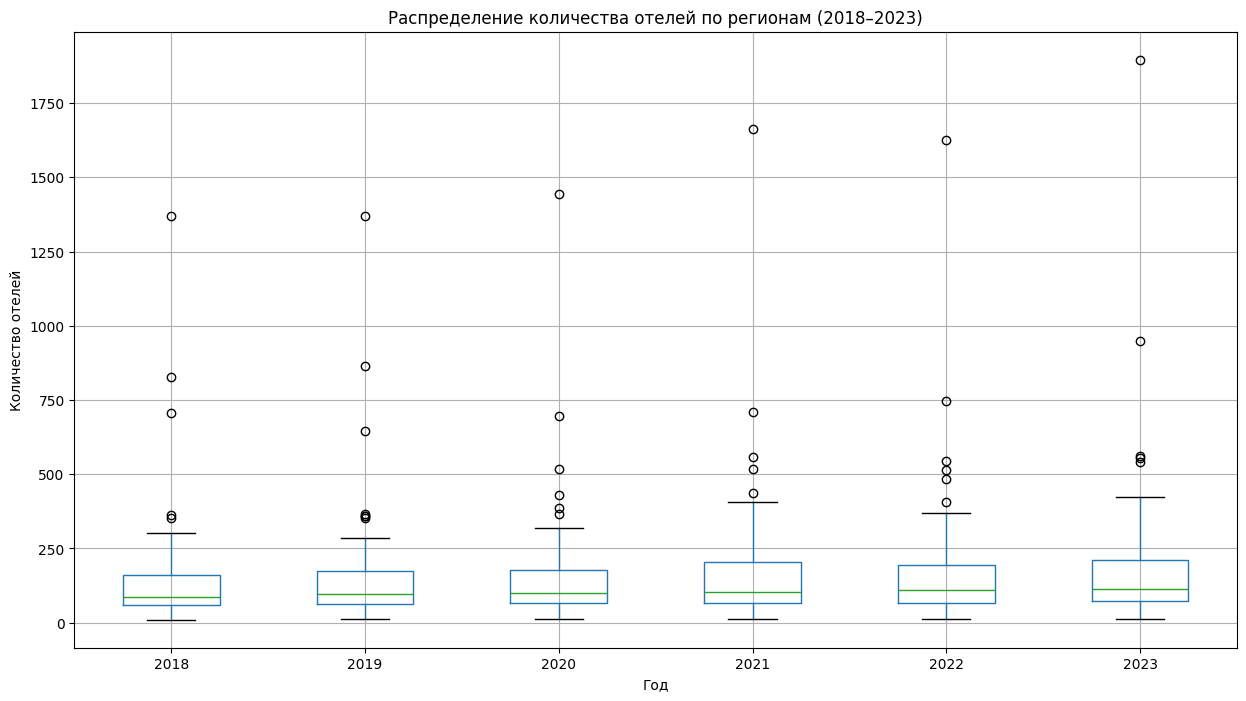

In [31]:
plt.figure(figsize=(15, 8))
hotel_selected.boxplot()
plt.title("Распределение количества отелей по регионам (2018–2023)")
plt.ylabel("Количество отелей")
plt.xlabel("Год")
plt.xticks(ticks=[1, 2, 3, 4, 5, 6], labels=["2018", "2019", "2020", "2021", "2022", "2023"])
plt.show()

Верхний «ус» (граница без учёта выбросов) постепенно увеличивается к 2023 году, что говорит о том, что в некоторых регионах число отелей стало выше.
Медиана (центральная линия) практически неизменна во все годы. Замечается незначительный медленный рост.

In [32]:
# Выбираем столбцы с количеством хостелов за каждый год
hostel_cols = [
    col for col in df_hotel.columns
        if col.startswith('hotels_')
]

# Проверяем, какие столбцы нашли
print(hostel_cols)

['hotels_2018', 'hotels_2019', 'hotels_2020', 'hotels_2021', 'hotels_2022', 'hotels_2023']


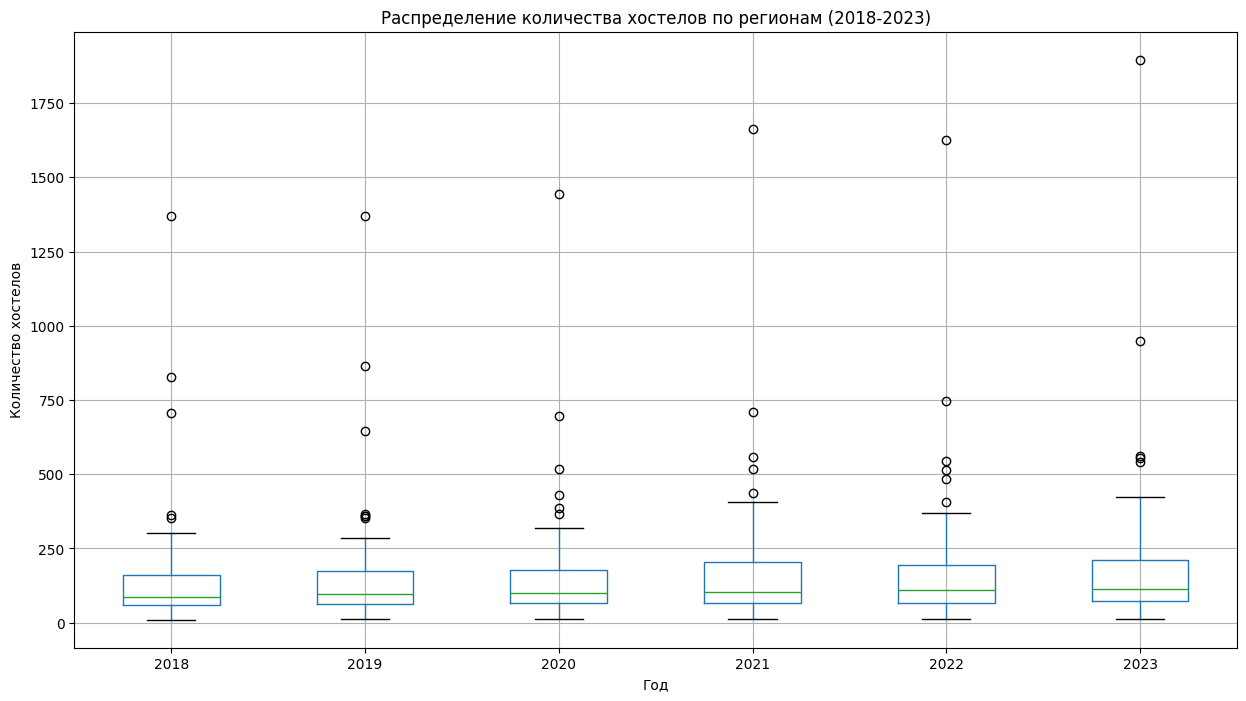

In [33]:
hostel_selected = df_hotel[hostel_cols]

plt.figure(figsize=(15, 8))
hostel_selected.boxplot()

plt.title('Распределение количества хостелов по регионам (2018-2023)')
plt.ylabel('Количество хостелов')
plt.xlabel('Год')
plt.xticks(
    ticks=[1, 2, 3, 4, 5, 6],
    labels=['2018', '2019', '2020', '2021', '2022', '2023']
)

plt.show()

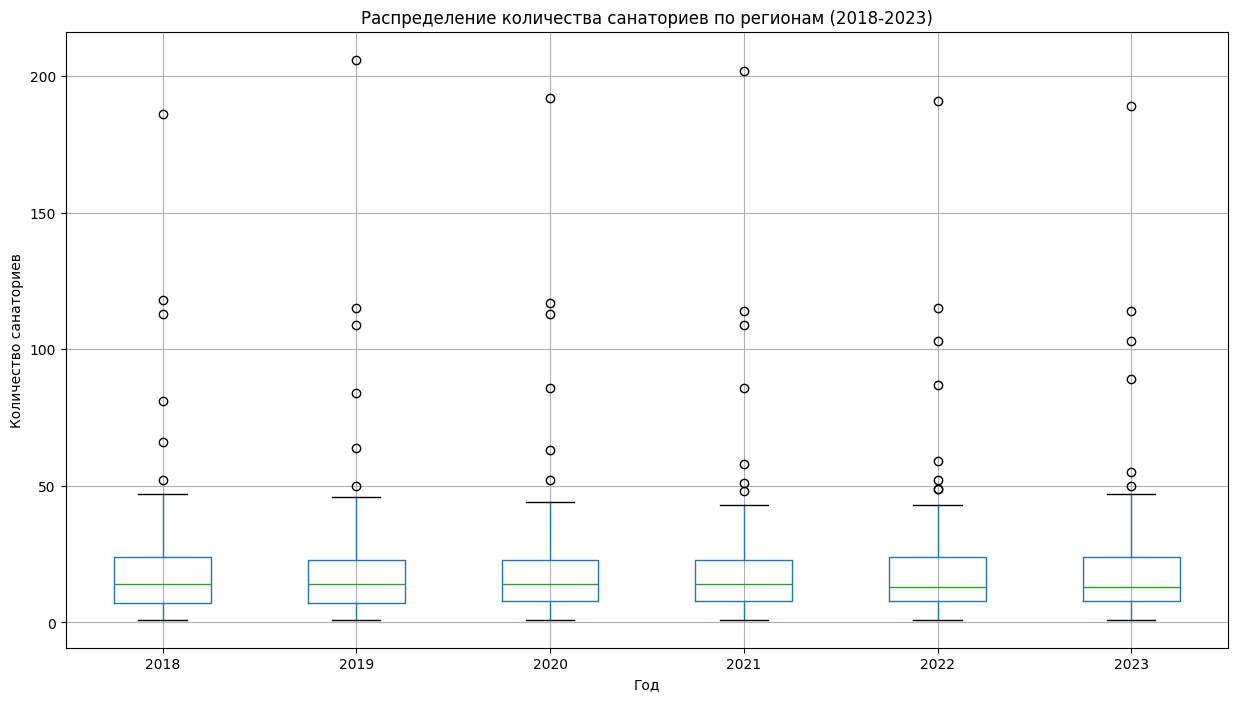

In [34]:
sanatorium_selected = df_hotel[
    ['sanatoriums_2018', 'sanatoriums_2019', 'sanatoriums_2020',
     'sanatoriums_2021', 'sanatoriums_2022', 'sanatoriums_2023']
]

plt.figure(figsize=(15, 8))
sanatorium_selected.boxplot()

plt.title('Распределение количества санаториев по регионам (2018-2023)')
plt.ylabel('Количество санаториев')
plt.xlabel('Год')
plt.xticks(
    ticks=[1, 2, 3, 4, 5, 6],
    labels=['2018', '2019', '2020', '2021', '2022', '2023']
)

plt.show()

#### Вывод: 
Распределение количества гостиниц и хостелов по регионам в 2018–2023 годах в целом остается относительно стабильным. При этом в отдельных регионах значения значительно выше основной массы, что отражается в виде выбросов.
Количество санаторно-курортных организаций имеет тенденцию к снижению: медианное значение постепенно уменьшается к 2023 году. Также наблюдаются отдельные регионы с существенно большим количеством санаториев по сравнению с большинством регионов.

In [35]:
!pip install seaborn 

In [36]:
import seaborn as sns

In [37]:
# Сортируем регионы по общей стоимости турпакетов
# от самого большого значения к самому маленькому
# и выбираем первые 10 строк
top_regions = df_tour_cost_2023.sort_values(
    by='total_cost_2023',
    ascending=False
).head(10)

# Выводим ТОП-10 регионов
top_regions


,subject,total_cost_2023,russia_cost_2023,foreign_cost_2023
17,г. Москва,388215.5477,61611.1085,325476.7008
9,Московская область,27151.9902,5059.5491,22081.5946
29,г. Санкт-Петербург,23785.7731,10176.0073,13211.9414
61,Тюменская область,14332.6665,2852.9022,11478.4233
60,Свердловская область,14271.0682,5029.2558,9230.5944
33,Краснодарский край,14250.5485,5754.7161,8464.1645
48,Республика Татарстан,13768.8762,3334.2739,10431.1633
51,Пермский край,12592.6389,5128.5544,7464.0845
53,Нижегородская область,11545.6481,5255.3996,6290.2485
73,Новосибирская область,10433.0335,2031.2164,8399.3291


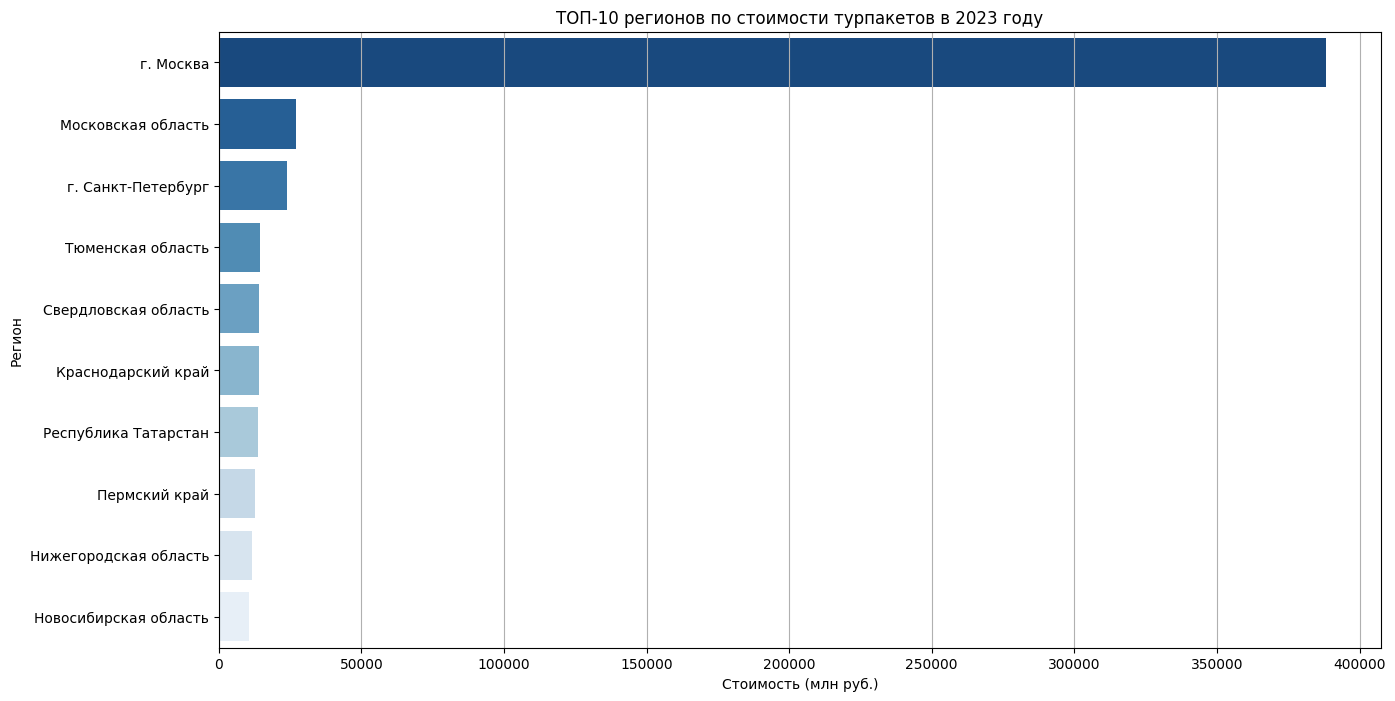

In [38]:
plt.figure(figsize=(15, 8))

sns.barplot(
    data=top_regions,
    x='total_cost_2023',
    y='subject',
    hue='subject',
    palette='Blues_r',
    legend=False
)

plt.title('ТОП-10 регионов по стоимости турпакетов в 2023 году')
plt.xlabel('Стоимость (млн руб.)')
plt.ylabel('Регион')
plt.grid(axis='x')
plt.show()

В 2023 году наибольшая стоимость турпакетов наблюдается в г. Москве, далее идут Московская область и г. Санкт-Петербург. Остальные регионы из ТОП-10 имеют значительно меньшие значения. Это показывает, что основная стоимость турпакетов сосредоточена в нескольких крупных регионах.

#### Задача 3.3. Построить линейный график, который покажет изменения среднего количества турпакетов в России по категориям с 2018 по 2023 год. 

In [39]:
# Рассчитываем среднее количество турпакетов по регионам для каждого года

years = list(range(2018, 2024))

avg_tours_people = [
    df_tour_firm[f'tours_people_{year}'].mean()
    for year in years
]

avg_tours_russia = [
    df_tour_firm[f'tours_russia_{year}'].mean()
    for year in years
]

avg_tours_foreign = [
    df_tour_firm[f'tours_foreign_{year}'].mean()
    for year in years
]

avg_tours_foreign_in_russia = [
    df_tour_firm[f'tours_foreign_in_russia_{year}'].mean()
    for year in years
]

# Выводим средние значения по годам в удобном виде

print('Среднее количество турпакетов по годам:')

for i, year in enumerate(years):
    print(
        f'{year}: '
        f'всего — {avg_tours_people[i]:.2f}; '
        f'гражданам России — {avg_tours_russia[i]:.2f}; '
        f'иностранцам за рубежом — {avg_tours_foreign[i]:.2f}; '
        f'иностранцам в России — {avg_tours_foreign_in_russia[i]:.2f}'
)

Среднее количество турпакетов по годам:
2018: всего — 58742.03; гражданам России — 20957.31; иностранцам за рубежом — 32586.14; иностранцам в России — 6046.66
2019: всего — 68328.76; гражданам России — 27014.91; иностранцам за рубежом — 37287.91; иностранцам в России — 5322.42
2020: всего — 40049.04; гражданам России — 26833.59; иностранцам за рубежом — 12979.85; иностранцам в России — 428.21
2021: всего — 60887.70; гражданам России — 36150.77; иностранцам за рубежом — 24283.12; иностранцам в России — 285.60
2022: всего — 67656.36; гражданам России — 38866.33; иностранцам за рубежом — 28294.97; иностранцам в России — 252.45
2023: всего — 79600.19; гражданам России — 41666.22; иностранцам за рубежом — 37143.38; иностранцам в России — 617.26


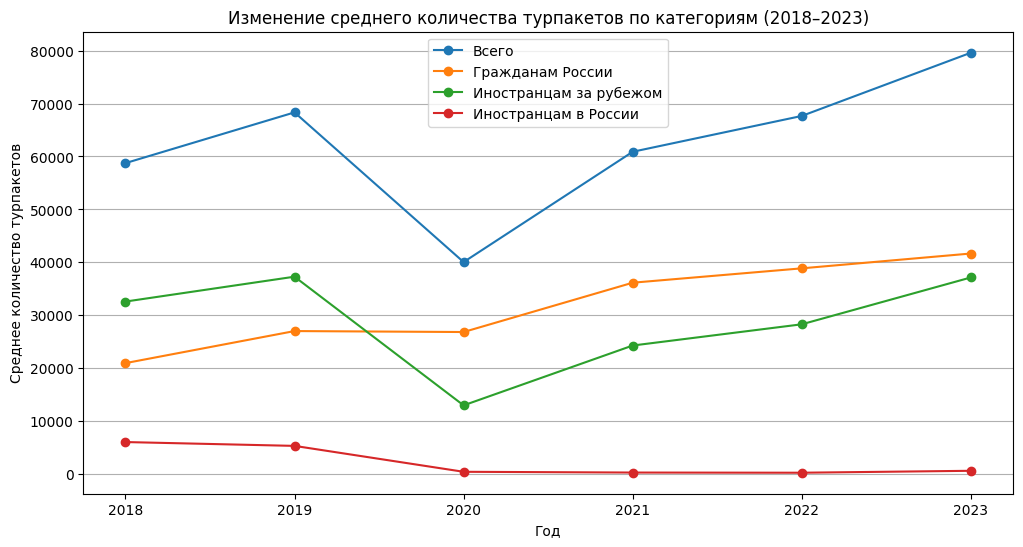

In [40]:
# Строим линейный график среднего количества турпакетов

plt.figure(figsize=(12, 6))

plt.plot(years, avg_tours_people, marker='o', label='Всего')
plt.plot(years, avg_tours_russia, marker='o', label='Гражданам России')
plt.plot(years, avg_tours_foreign, marker='o', label='Иностранцам за рубежом')
plt.plot(years, avg_tours_foreign_in_russia, marker='o', label='Иностранцам в России')

plt.title('Изменение среднего количества турпакетов по категориям (2018–2023)')
plt.xlabel('Год')
plt.ylabel('Среднее количество турпакетов')

plt.xticks(years)
plt.grid(axis='y')
plt.legend()

plt.show()

В 2020 году наблюдается резкое снижение среднего количества турпакетов по всем категориям. С 2021 года показатели постепенно восстанавливаются и к 2023 году достигают максимальных значений за рассматриваемый период. Наибольшее среднее количество турпакетов приходится на внутренний рынок

### Шаг 4. Проверка гипотез

#### Задание 4.1. Проверка гипотезы с одной выборкой

Туристическая индустрия является важной частью экономики, и анализ её показателей позволяет выявить тренды и оценить эффективность работы рынка. Один из ключевых показателей — средняя стоимость реализованных турпакетов.

Существует мнение, что средняя стоимость реализованных турпакетов в 2023 году составила 800 млн рублей. Однако аналитики подозревают, что этот показатель может быть больше. Задача — провести статистический тест, который поможет определить, можно ли отвергнуть нулевую гипотезу в пользу альтернативной.

In [41]:
df_tour_cost_2023['total_cost_2023'].describe()

count        85.000000
mean       8579.186196
std       41961.924483
min          31.232000
25%        1098.784400
50%        2599.052900
75%        4927.968000
max      388215.547700
Name: total_cost_2023, dtype: float64

In [42]:
# Переводим стоимость из тысяч рублей в миллионы рублей
df_tour_cost_2023['total_cost_2023_mln'] = (
    df_tour_cost_2023['total_cost_2023'] / 1000
)

# Проверяем результат
df_tour_cost_2023['total_cost_2023_mln'].describe()

count     85.000000
mean       8.579186
std       41.961924
min        0.031232
25%        1.098784
50%        2.599053
75%        4.927968
max      388.215548
Name: total_cost_2023_mln, dtype: float64

Нужно проверить одностороннюю гипотезу:

H0: Средняя стоимость реализованных турпакетов в 2023 году (млн рублей) = 800
H1: Средняя стоимость реализованных турпакетов в 2023 году (млн рублей) > 800

In [43]:
!pip install scipy

In [44]:
from scipy import stats as st
import numpy as np

In [45]:
# Убираем пропуски из столбца со стоимостью турпакетов
total_tour_cost_2023 = df_tour_cost_2023['total_cost_2023_mln'].dropna()

# Задаём ожидаемое среднее значение стоимости турпакетов
# По нулевой гипотезе средняя стоимость равна 800 млн рублей
expected_mean_tour_cost = 800

# Задаём уровень статистической значимости
alpha = 0.05

# Выполняем односторонний t-тест
# Проверяем гипотезу о том, что средняя стоимость больше 800 млн рублей
results = st.ttest_1samp(
    total_tour_cost_2023,
    expected_mean_tour_cost,
    alternative='greater'
)

# Выводим p-значение
print('p-значение:', results.pvalue)

# Сравниваем p-значение с уровнем значимости
if results.pvalue < alpha:
    print('Отвергаем нулевую гипотезу')
else:
    print('Не получилось отвергнуть нулевую гипотезу')

p-значение: 1.0
Не получилось отвергнуть нулевую гипотезу


Оснований отвергнуть нулевую гипотезу нет. То есть по имеющимся данным мы не можем утверждать, что средняя стоимость турпакета в 2023 году превышает 800 млн ₽.

#### Задание 4.2. Проверка гипотезы с двумя выборками

Статистика говорит, что в 2023 году, по сравнению с 2022, россияне стали чаще ездить по стране и оформлять турпакеты. Проверим статистическую гипотезу о том, стало ли в 2023 году больше проданных турпакетов по России, чем в 2022 году.

Проверим одностороннюю гипотезу:

H0: Среднее количество турпакетов, реализованных в 2022 году = Среднему количеству турпакетов, реализованных в 2023 году
H1: Среднее количество турпакетов, реализованных в 2022 году < Cреднего количества турпакетов, реализованных в 2023 году

In [48]:
# Среднее количество турпакетов по России в 2023 году
df_tour_firm['tours_russia_2023'].mean()

np.float64(41666.225)

In [51]:
# Среднее количество турпакетов по России в 2023 году
df_tour_firm['tours_russia_2022'].mean()

np.float64(38866.333333333336)

In [50]:
# Выбираем данные за 2022 год
tours_russia_2022 = df_tour_firm['tours_russia_2022']

# Выбираем данные за 2023 год
tours_russia_2023 = df_tour_firm['tours_russia_2023']

# Уровень статистической значимости
alpha = 0.05

In [54]:
# Убираем пропуски из данных
tours_russia_2022 = tours_russia_2022.dropna()
tours_russia_2023 = tours_russia_2023.dropna()

# Проводим односторонний t-тест
# Проверяем, стало ли в 2023 году больше турпакетов,
# чем в 2022 году

results = st.ttest_ind(
    tours_russia_2022,
    tours_russia_2023,
    alternative='less'
)

# Выводим p-значение
print('p-значение:', results.pvalue)
# Сравниваем p-значение с уровнем значимости
if results.pvalue < alpha:
    print('Отвергаем нулевую гипотезу')
else:
    print('Не получилось отвергнуть нулевую гипотезу')

p-значение: 0.44915342190717794
Не получилось отвергнуть нулевую гипотезу


### Итоговые выводы по исследованию

**1. Подготовка данных**

В ходе анализа данные были проверены и подготовлены к исследованию: числовые показатели приведены к числовому типу, пропуски учитывались при расчётах, после чего данные были готовы для статистического анализа и визуализации.

**2. Стоимость реализованных турпакетов в 2023 году**

В 2023 году средняя стоимость реализованных турпакетов по нашим данным составила примерно 8,58 млн рублей.

Проверили гипотезу о том, что средняя стоимость турпакета превышает 800 млн рублей. Статистических оснований утверждать это по нашим данным не получили.

То есть в выводе лучше написать:

Средняя стоимость реализованных турпакетов в 2023 году по исследуемым данным не подтверждает предположение о превышении 800 млн рублей.

**3. Регионы с наибольшей стоимостью турпакетов**

Наибольшая суммарная стоимость реализованных турпакетов в 2023 году наблюдалась в крупнейших туристических и экономических регионах. В частности, среди лидеров оказались Москва, Московская область и Санкт-Петербург.

При этом Москва заметно выделяется по объёму стоимости турпакетов относительно остальных регионов.

**4. Динамика количества турпакетов**

По графику за 2018–2023 годы видно изменение количества реализованных турпакетов по категориям. На динамику особенно повлиял 2020 год, после которого показатели начали восстанавливаться.

При этом к 2023 году показатели по некоторым категориям достигли более высоких значений по сравнению с предыдущими годами.

**5. Сравнение 2022 и 2023 годов**

Среднее количество турпакетов по России:

* 2022: 38 866,33
* 2023: 41 666,23

То есть в 2023 году среднее значение действительно было выше примерно на 7,2%.

Но одного увеличения среднего недостаточно, поэтому мы провели статистический тест.
Несмотря на увеличение среднего количества реализованных турпакетов в 2023 году по сравнению с 2022 годом, статистически значимых оснований утверждать, что в 2023 году среднее количество турпакетов стало выше, недостаточно.